# LAB 2 – Bài 6: Phân lớp nấm độc / ăn được – Mushroom (Trang 27)
Thực hiện lại từ Câu 4 của phần *Yêu cầu lập trình*. Thuộc tính quyết định: `class` (`p` = độc, `e` = ăn được). Cần file `mushrooms.csv`.


In [1]:

HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"

def in_ten():
    print(f"{HO_TEN} - {MSSV}")

in_ten()

Lê Quốc Trung - 6451071082


## Chuẩn bị: thư viện và hàm dùng chung

In [2]:
%matplotlib inline
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


import urllib.request

# ID file trên Google Drive (lấy từ link chia sẻ .../file/d/<ID>/view)
FILE_IDS = {
    "adult.data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult.test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
}


def tai_tu_drive(file_id, ten_luu):
    """Tải file công khai từ Google Drive theo ID và lưu thành ten_luu."""
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        noi_dung = r.read()
    if noi_dung.lstrip()[:15].lower().startswith((b"<!doctype html", b"<html")):
        raise RuntimeError("Drive trả về trang web thay vì file: kiểm tra file đã chia sẻ 'Bất kỳ ai có đường liên kết' chưa.")
    with open(ten_luu, "wb") as f:
        f.write(noi_dung)


def tim_file(ten_file):
    """Trả về đường dẫn file dữ liệu: dùng bản có sẵn trong máy, nếu chưa có thì tải từ Drive theo FILE_IDS."""
    for thu_muc in [".", "data", "/content"]:
        p = os.path.join(thu_muc, ten_file)
        if os.path.isfile(p):
            print("Đã tìm thấy:", p)
            return p
    if ten_file not in FILE_IDS:
        raise FileNotFoundError(f"Không có file '{ten_file}' và cũng không có ID Drive tương ứng.")
    print(f"Đang tải '{ten_file}' từ Google Drive...")
    tai_tu_drive(FILE_IDS[ten_file], ten_file)
    print("Đã tải xong:", ten_file)
    return ten_file


ket_qua = {}   # lưu chỉ số của từng mô hình để so sánh ở Câu 10


def tinh_chi_so(y_true, y_pred, pos_label=None):
    d = {"Accuracy": metrics.accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = metrics.precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        d[f"Precision ({avg})"], d[f"Recall ({avg})"], d[f"F1 ({avg})"] = p, r, f
    if pos_label is not None:
        p, r, f, _ = metrics.precision_recall_fscore_support(
            y_true, y_pred, labels=[pos_label], average=None, zero_division=0)
        d[f"Precision [{pos_label}]"], d[f"Recall [{pos_label}]"], d[f"F1 [{pos_label}]"] = p[0], r[0], f[0]
    return d


def danh_gia_mo_hinh(ten, y_test, y_pred, labels, pos_label=None, cmap="Blues"):
    """In accuracy + classification report, vẽ heatmap ma trận nhầm lẫn, lưu chỉ số để so sánh."""
    score = metrics.accuracy_score(y_test, y_pred)
    print("Accuracy:", score)
    print("Report:\n", metrics.classification_report(y_test, y_pred, labels=labels, zero_division=0))
    cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.title(f"{ten} Accuracy Score: {score:.4f}", size=15)
    plt.show()
    ket_qua[ten] = tinh_chi_so(y_test, y_pred, pos_label)
    return cm


def ve_cay(clf, feature_names, ten_file, max_depth=None, figsize=(50, 24), fontsize=10):
    """Vẽ cây quyết định và lưu thành file PNG (dpi=100)."""
    fig, ax = plt.subplots(figsize=figsize)
    tree.plot_tree(clf, max_depth=max_depth, feature_names=list(feature_names),
                   class_names=[str(c) for c in clf.classes_], filled=True, fontsize=fontsize, ax=ax)
    plt.savefig(ten_file, dpi=100)
    plt.show()
    print("Đã lưu cây vào file:", ten_file)

## Chuẩn bị: nhập dữ liệu

In [3]:
in_ten()
data = pd.read_csv(tim_file("mushrooms.csv"))
print("Kích thước:", data.shape)
print("Số ô trống:", int(data.isna().sum().sum()))
print("Ký hiệu '?' (nếu có) được giữ nguyên như một giá trị phân loại:",
      int((data == "?").sum().sum()), "ô")
data.info()
display(data.head())

Lê Quốc Trung - 6451071082
Đang tải 'mushrooms.csv' từ Google Drive...
Đã tải xong: mushrooms.csv
Kích thước: (8124, 23)
Số ô trống: 0
Ký hiệu '?' (nếu có) được giữ nguyên như một giá trị phân loại: 2480 ô
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [4]:
NHAN = "class"   # thuộc tính quyết định

## Câu 4: Tách các cột thành hai phần
`features` chứa các thuộc tính bình thường, `labels` chứa riêng thuộc tính quyết định.

In [5]:
in_ten()
features = data.drop(NHAN, axis=1)
labels = data[NHAN]
print("features:", features.shape, "| labels:", labels.shape)
print(labels.value_counts())

Lê Quốc Trung - 6451071082
features: (8124, 22) | labels: (8124,)
class
e    4208
p    3916
Name: count, dtype: int64


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Xác định các cột không phải dạng số rồi dùng `pd.get_dummies`.

In [6]:
in_ten()
cot_chu = features.select_dtypes(exclude="number").columns
print("Các cột không phải dạng số:", list(cot_chu))

if len(cot_chu) > 0:
    features_onehot = pd.get_dummies(features, columns=cot_chu, dtype=int)
else:
    features_onehot = features.copy()
    print("=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.")

print("Kích thước sau khi xử lý:", features_onehot.shape)
display(features_onehot.head())

Lê Quốc Trung - 6451071082
Các cột không phải dạng số: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
Kích thước sau khi xử lý: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Câu 6: Chia dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)
Theo đề: `train_test_split(X, y, test_size=0.3, random_state=42)`.

In [7]:
in_ten()
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

LOP = sorted(labels.unique())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Các lớp:", LOP)

Lê Quốc Trung - 6451071082
X_train: (5686, 117) | X_test: (2438, 117)
Các lớp: ['e', 'p']


## Câu 7: Xây dựng cây ID3 (`criterion="entropy"` – phân nhánh theo information gain)
Gồm 3 phần: huấn luyện + dự đoán → kiểm thử bằng ma trận nhầm lẫn → biểu diễn cây.

In [8]:
in_ten()
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)          # huấn luyện
id3_pred = clf_id3.predict(X_test)     # dự đoán trên dữ liệu kiểm thử
print("Số nút:", clf_id3.tree_.node_count, "| số lá:", clf_id3.get_n_leaves(), "| độ sâu:", clf_id3.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 21 | số lá: 11 | độ sâu: 5


Lê Quốc Trung - 6451071082
Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



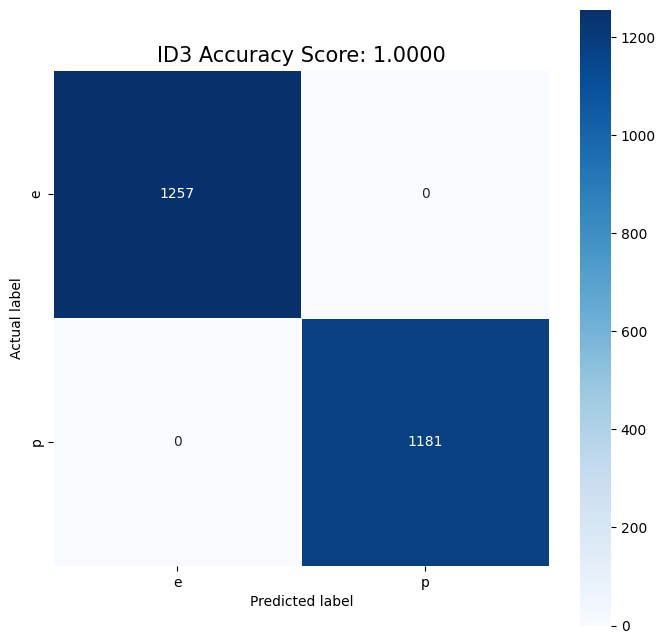

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[1257    0]
 [   0 1181]]


In [9]:
in_ten()
id3_cm = danh_gia_mo_hinh("ID3", y_test, id3_pred, LOP, pos_label='p', cmap="Blues")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(id3_cm)

Lê Quốc Trung - 6451071082


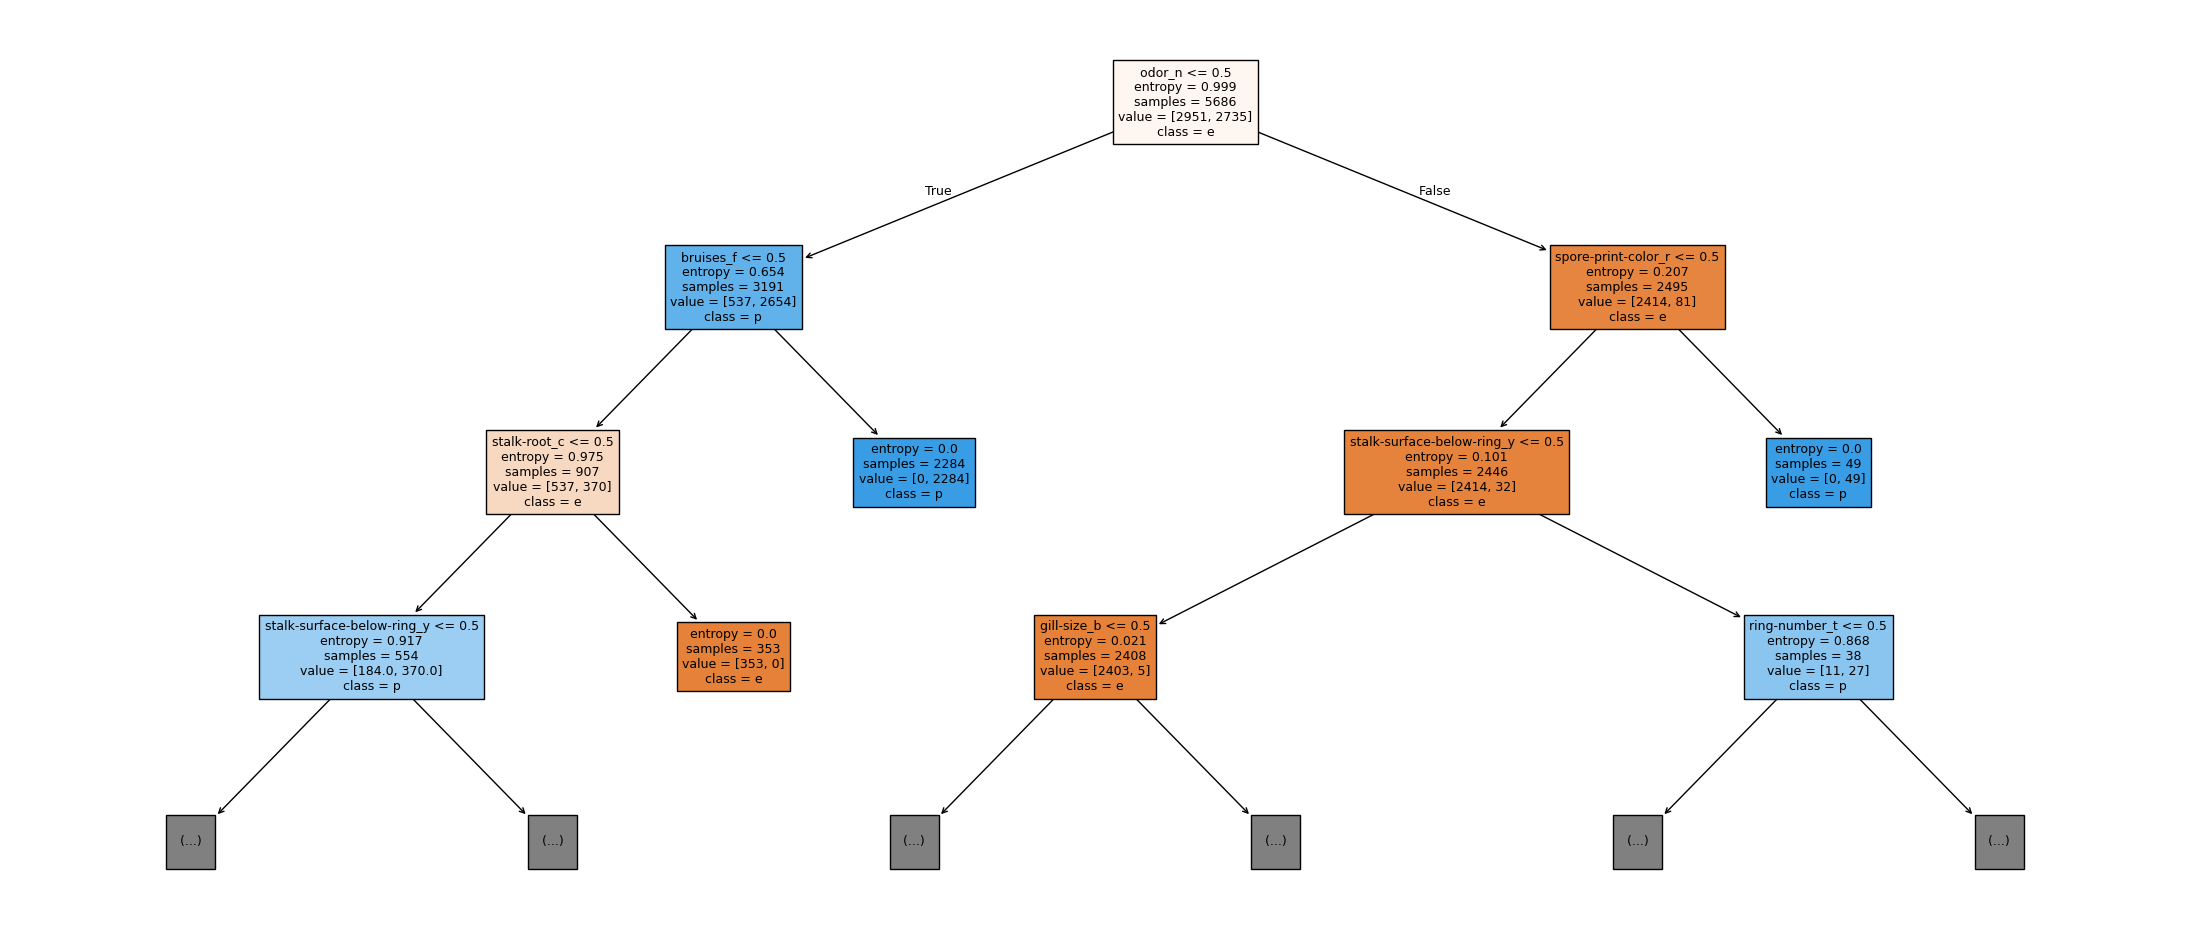

Đã lưu cây vào file: cay_ID3_rut_gon.png


In [10]:
in_ten()
# Cây rút gọn (3 mức trên cùng) để đọc được trên màn hình
ve_cay(clf_id3, X_train.columns, "cay_ID3_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


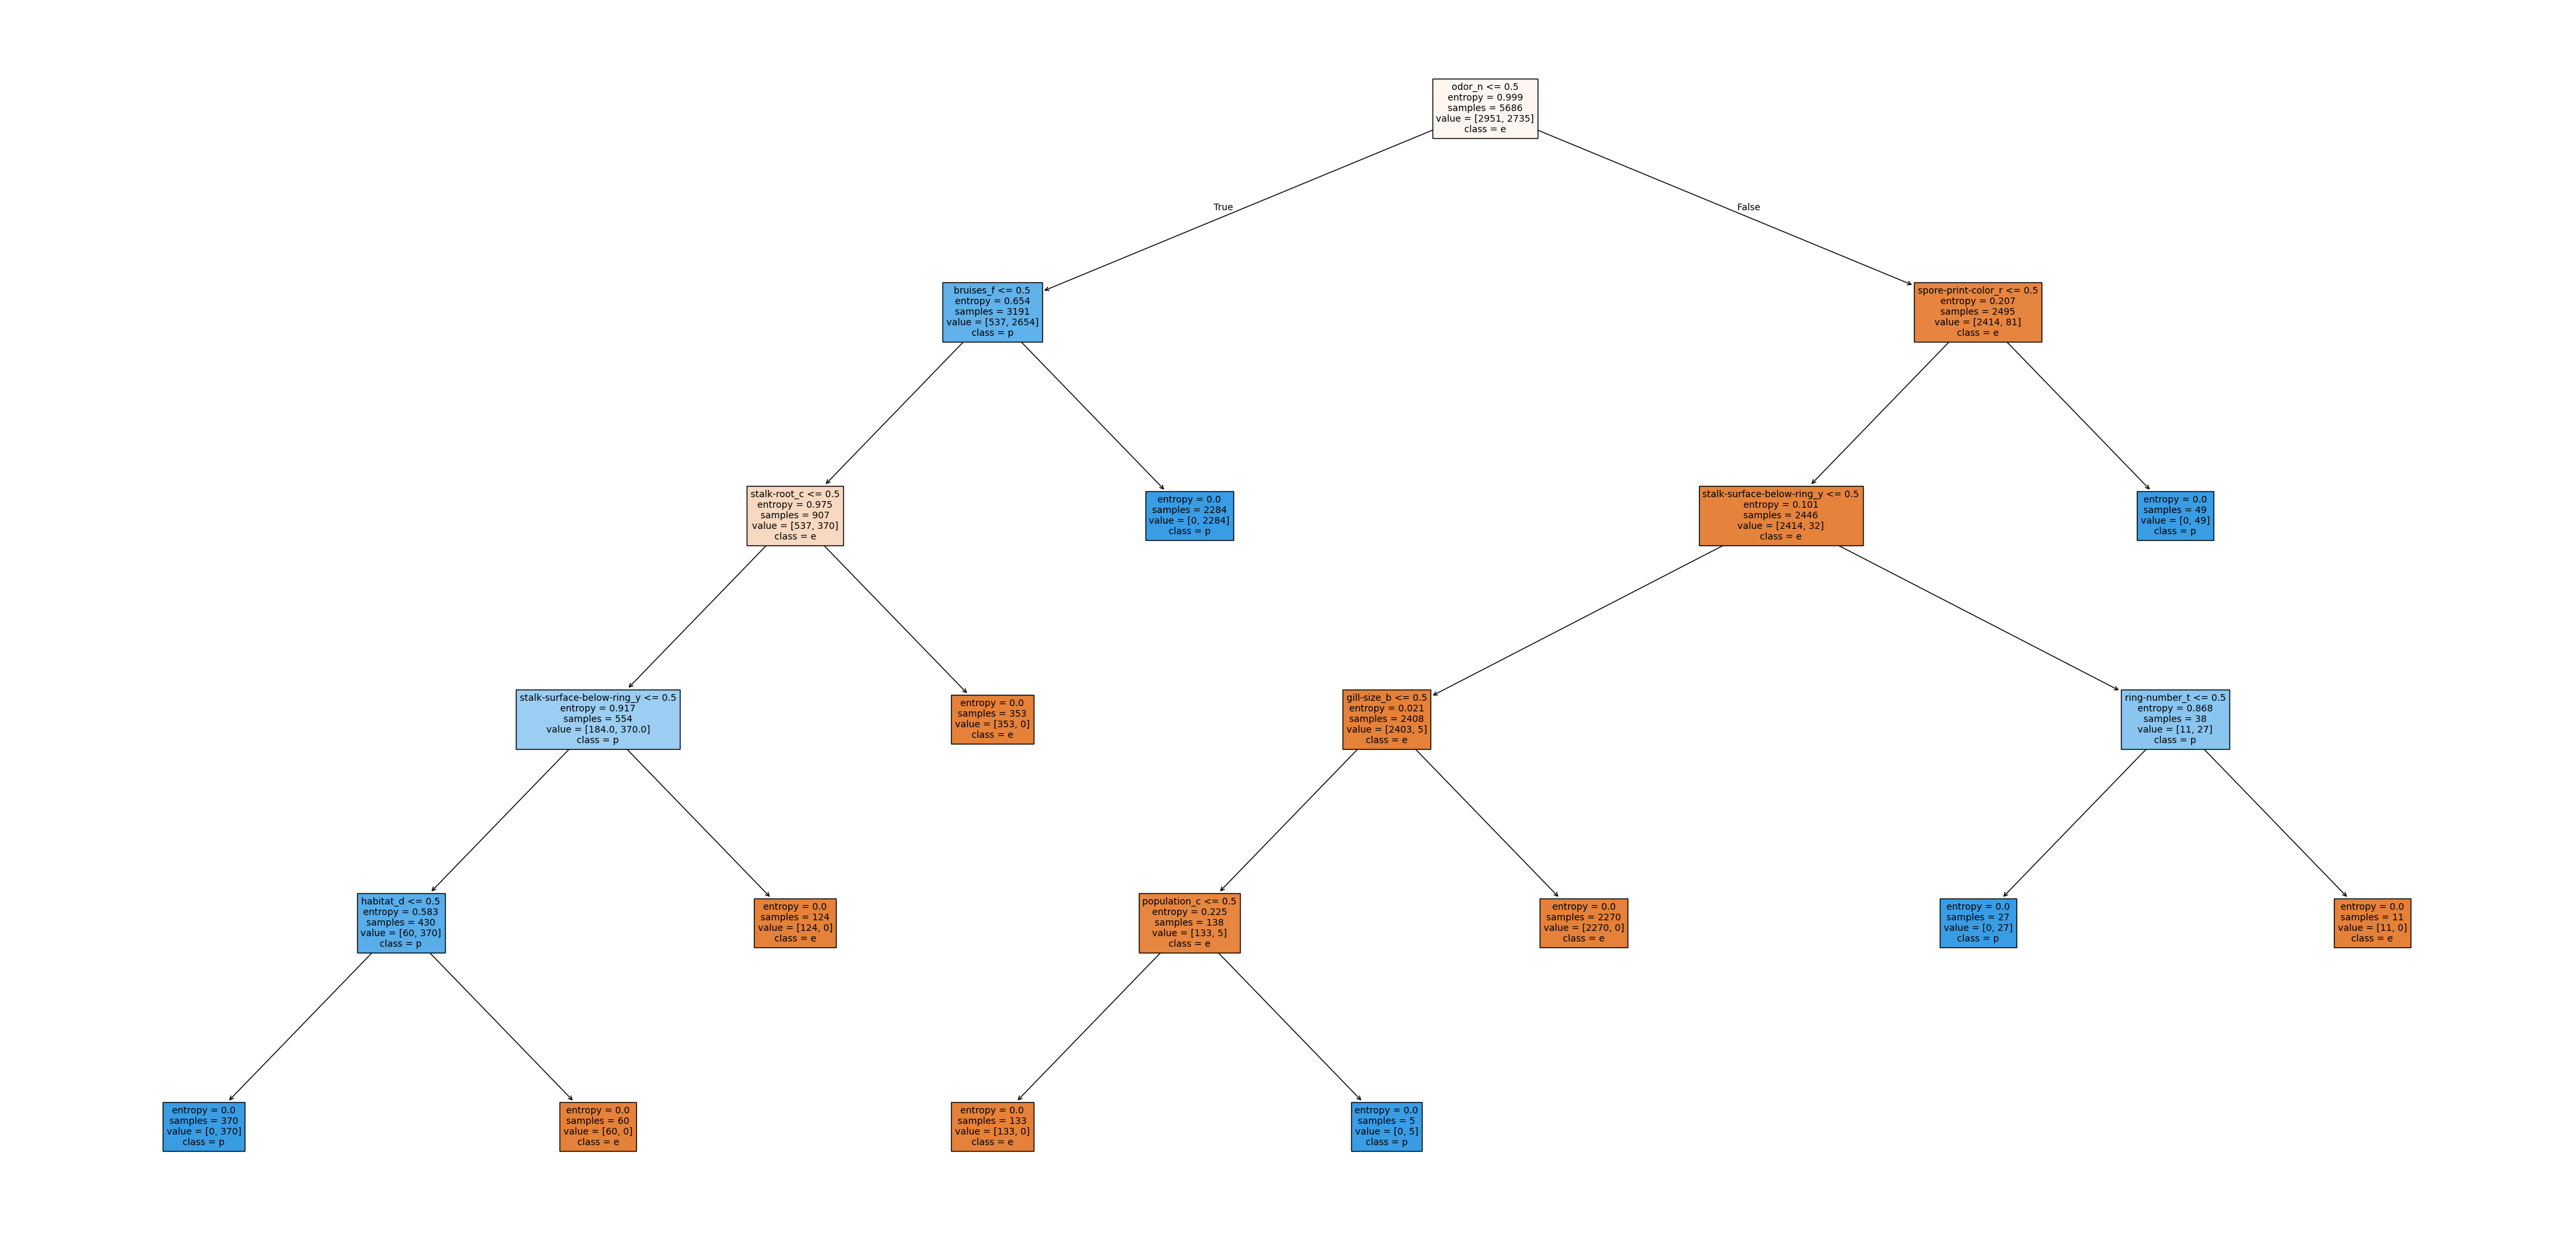

Đã lưu cây vào file: cay_ID3.png


In [11]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_id3, X_train.columns, "cay_ID3.png", figsize=(50, 24), fontsize=10)

## Câu 8: Xây dựng cây CART (`criterion="gini"`)
Thực hiện tương tự Câu 7, thay `criterion="gini"`.

In [12]:
in_ten()
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)
print("Số nút:", clf_cart.tree_.node_count, "| số lá:", clf_cart.get_n_leaves(), "| độ sâu:", clf_cart.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 27 | số lá: 14 | độ sâu: 7


Lê Quốc Trung - 6451071082
Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



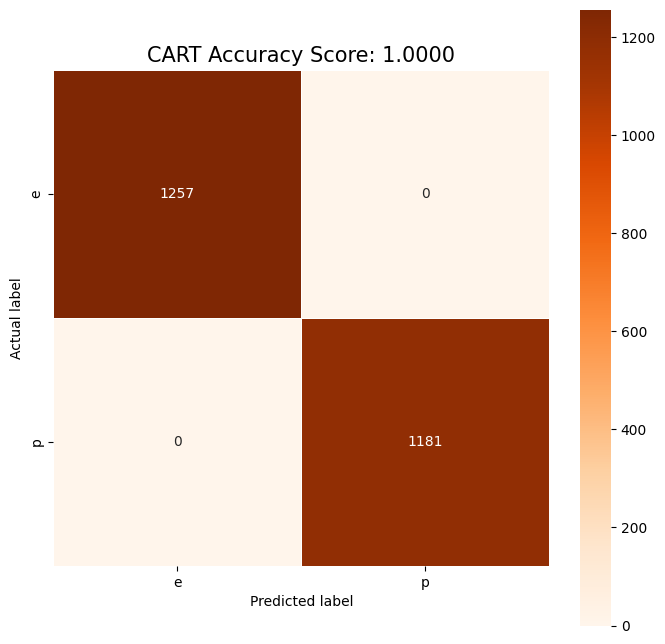

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[1257    0]
 [   0 1181]]


In [13]:
in_ten()
cart_cm = danh_gia_mo_hinh("CART", y_test, cart_pred, LOP, pos_label='p', cmap="Oranges")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(cart_cm)

Lê Quốc Trung - 6451071082


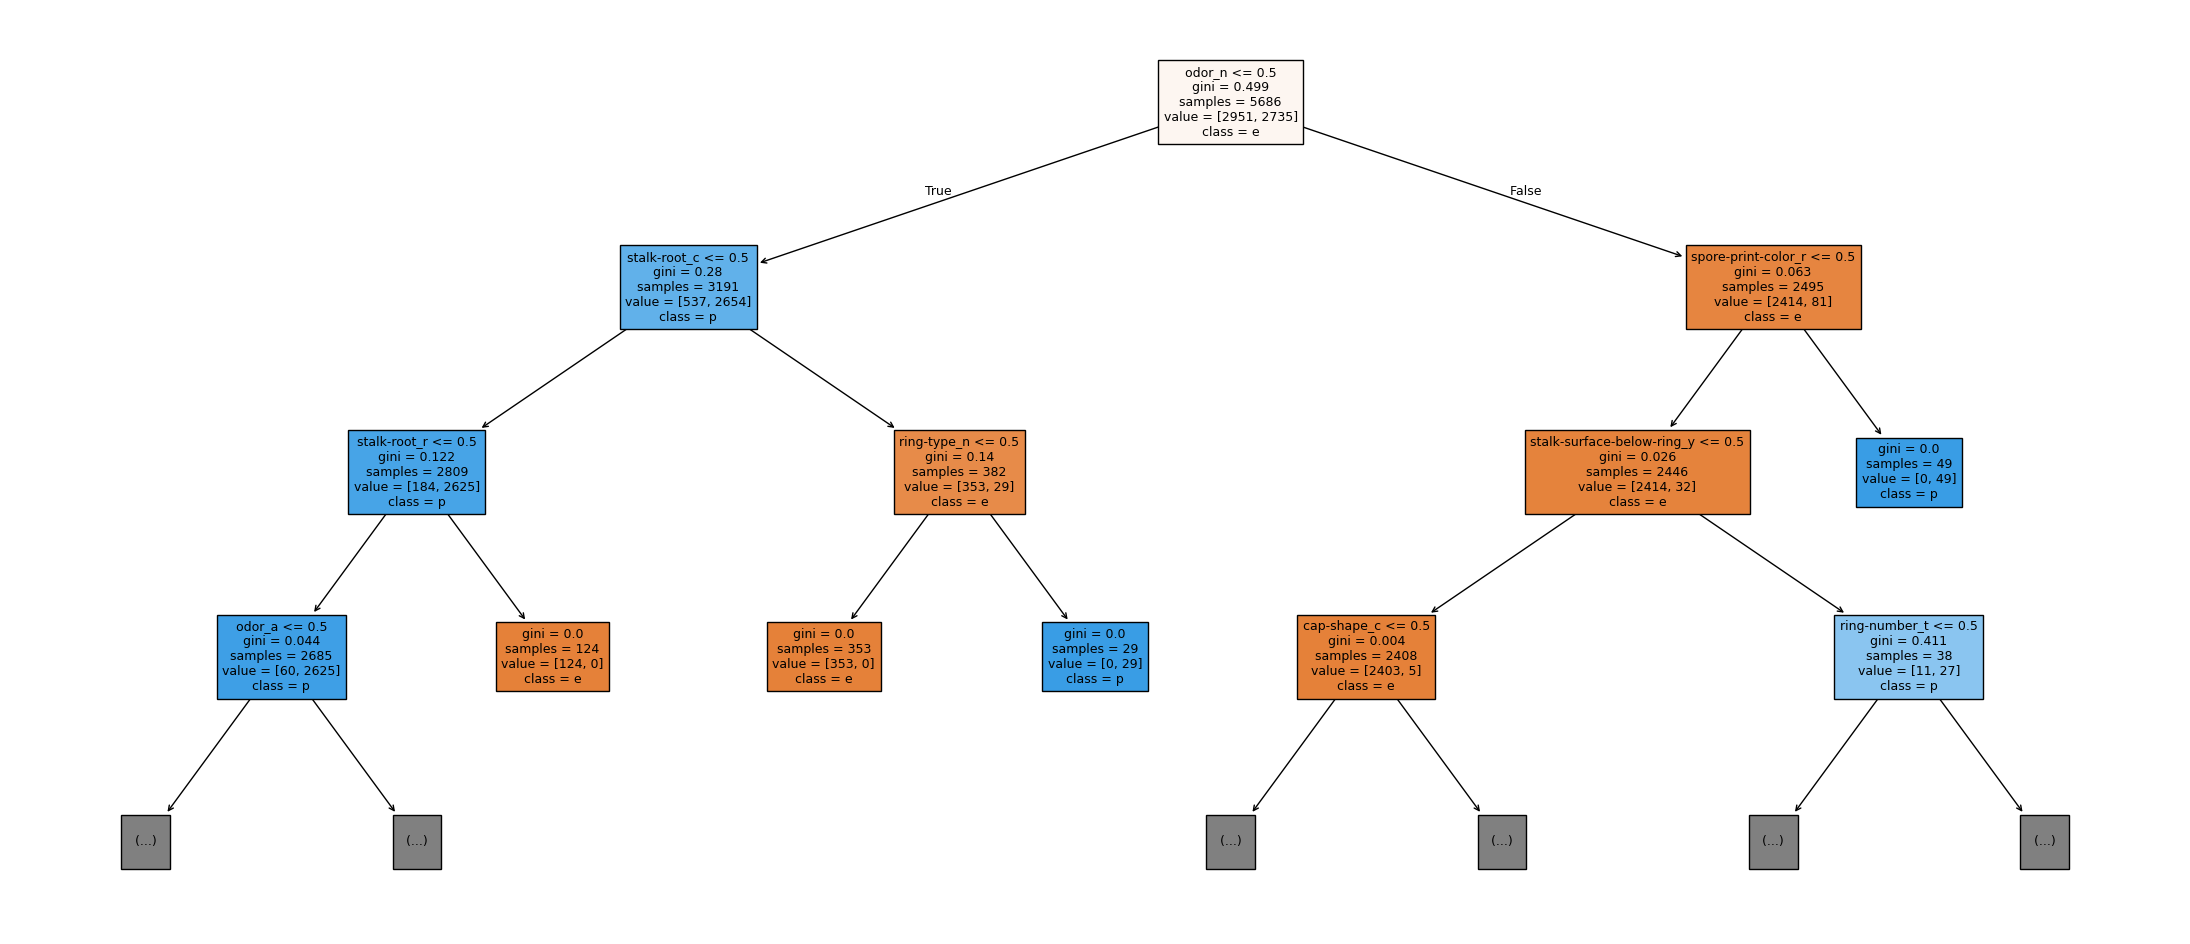

Đã lưu cây vào file: cay_CART_rut_gon.png


In [14]:
in_ten()
ve_cay(clf_cart, X_train.columns, "cay_CART_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


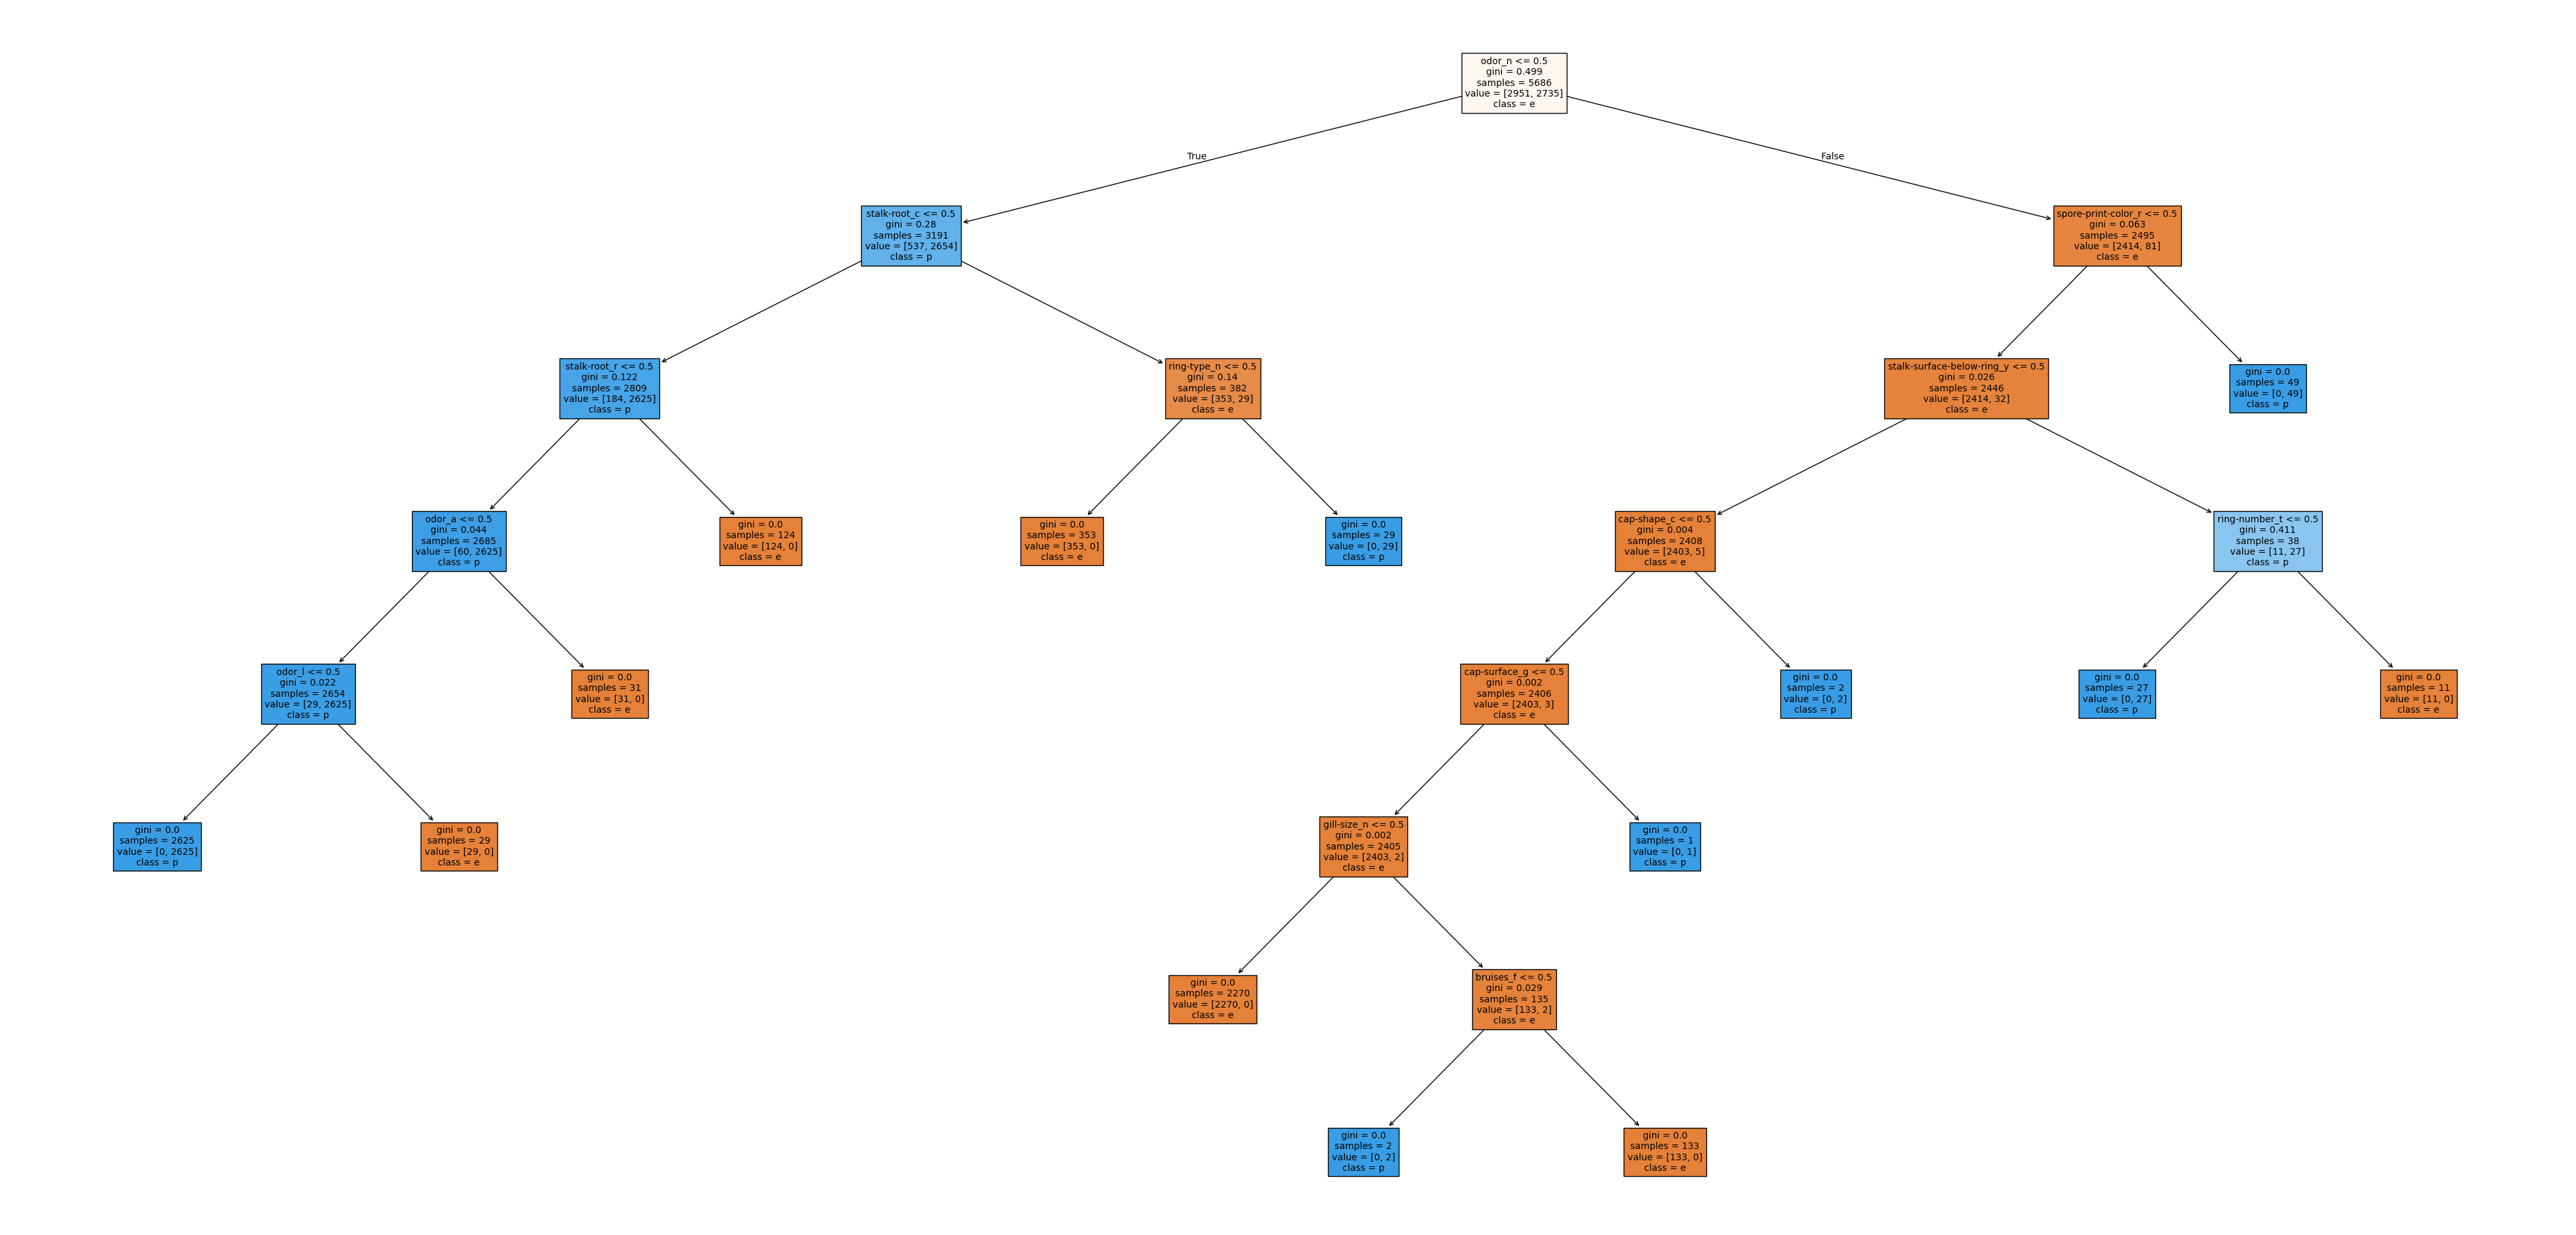

Đã lưu cây vào file: cay_CART.png


In [15]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_cart, X_train.columns, "cay_CART.png", figsize=(50, 24), fontsize=10)

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`)

In [16]:
in_ten()
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Lê Quốc Trung - 6451071082


Lê Quốc Trung - 6451071082
Accuracy: 0.9643150123051681
Report:
               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



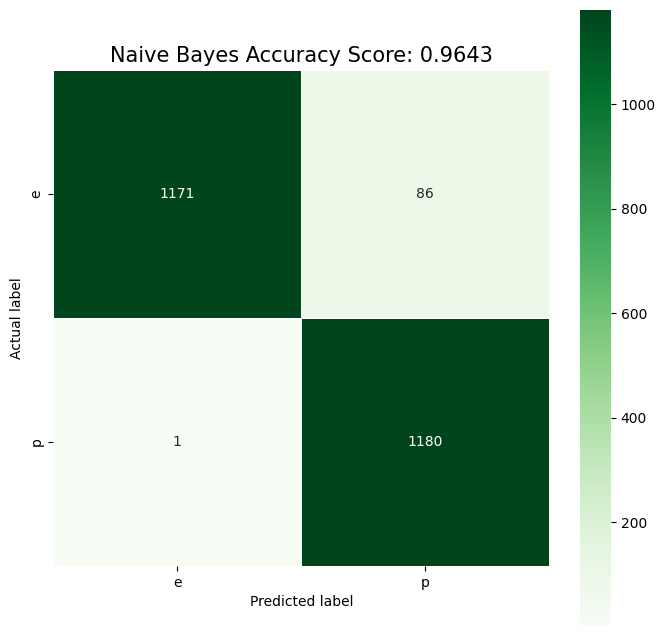

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[1171   86]
 [   1 1180]]


In [17]:
in_ten()
bayes_cm = danh_gia_mo_hinh("Naive Bayes", y_test, bayes_pred, LOP, pos_label='p', cmap="Greens")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(bayes_cm)

## Câu 10: So sánh kết quả của các mô hình

Lê Quốc Trung - 6451071082


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Precision [p],Recall [p],F1 [p]
ID3,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
CART,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Naive Bayes,0.9643,0.9656,0.9654,0.9643,0.9667,0.9643,0.9643,0.9321,0.9992,0.9644


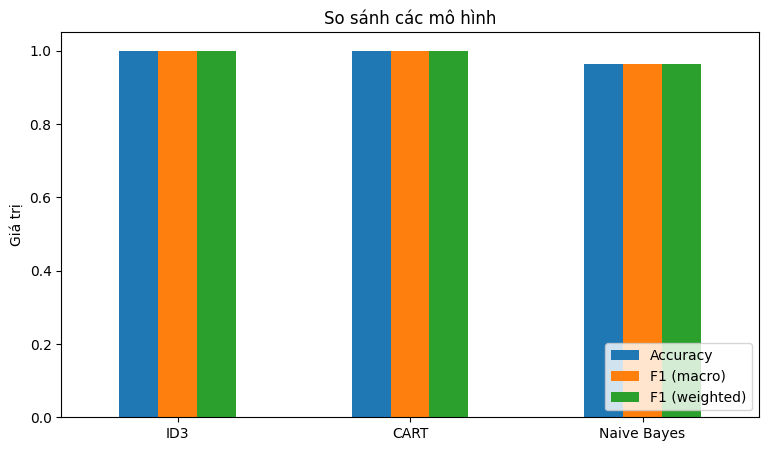

Mô hình có Accuracy cao nhất  : ID3 (1.0000)
Mô hình có F1 (macro) cao nhất: ID3 (1.0000)


In [18]:
in_ten()
bang_ss = pd.DataFrame(ket_qua).T.round(4)
display(bang_ss)

bang_ss[["Accuracy", "F1 (macro)", "F1 (weighted)"]].plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("So sánh các mô hình")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

print("Mô hình có Accuracy cao nhất  :", bang_ss["Accuracy"].idxmax(), f"({bang_ss['Accuracy'].max():.4f})")
print("Mô hình có F1 (macro) cao nhất:", bang_ss["F1 (macro)"].idxmax(), f"({bang_ss['F1 (macro)'].max():.4f})")

### Nhận xét (đối chiếu với bảng số liệu ở trên rồi chỉnh lại cho khớp kết quả chạy thực tế)
- Dữ liệu nấm gần như **tách được hoàn toàn** theo vài thuộc tính (vd. `odor`, `spore-print-color`) nên ID3 và CART thường đạt Accuracy rất cao (có thể 100%).
- `GaussianNB` thường thấp hơn vì các cột sau one-hot là nhị phân (không phải phân phối chuẩn) và nhiều cột phụ thuộc nhau; có thể thử `CategoricalNB`/`BernoulliNB` phù hợp hơn.
- Với bài toán này, lỗi nguy hiểm nhất là **nấm độc bị dự đoán là ăn được** (FN của lớp `p`) → cần nhìn **recall của lớp `p`** chứ không chỉ Accuracy.